# Part I - Base de dados emissão de poluentes

# 1. EXTRAÇÃO (Extract)
Coleta de dados brutos, arquivo CSV.

## 1.1. PREPARAÇÃO DO AMBIENTE

**Pandas**
- Leitura e escrita de arquivos;
- Limpeza de dados;
- Filtragem e seleção;
- Transformação e agregação;
- Combinação de tabelas.

**Numpy**
- Álgebra Linear e Matemática;
- Base para outros pacotes

**Matplotlib**
- Geração de gráficos
- Personalização visual
- Controle interativo e exportação

**Seaborn**
- Geração de gráficos com visual mais refinado,
- Estatística embutida



In [1]:
# Importando Bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
# Configuração para melhorar a visualização
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [3]:
# Leitura do arquivo em CSV
df = pd.read_csv('/content/gases_correta.csv')

### 1.1.1. LEITURA DE UMA AMOSTRA

Etapa preliminar onde apresentaremos informações básicas do banco de dados como:
- Dimensões da amostra;
- Nome de cada uma das colunas;
- Tipo de dados presente em cada uma das colunas.

In [4]:
# Identificar automaticamente o separador
try:
    amostra = pd.read_csv('/content/gases_correta.csv',
        sep=None,
        engine='python',
        encoding='utf-8-sig',
        nrows=5
    )
except UnicodeDecodeError:
    amostra = pd.read_csv('/content/gases_correta.csv',
        sep=None,
        engine='python',
        encoding='latin1',
        nrows=5
    )

In [5]:
# Exibir informações da amostra
print("DIMENSÕES DA AMOSTRA:")
print(amostra.shape)

print("\nNOMES DAS COLUNAS:")
print(amostra.columns.tolist())

print("\nTIPOS DE DADOS:")
print(amostra.dtypes)

print("\nPRIMEIROS REGISTROS:")
display(amostra)

print("\nSEPARADOR IDENTIFICADO:")
print(repr(amostra.attrs.get('sep', 'Verificar separador no arquivo')))

DIMENSÕES DA AMOSTRA:
(5, 68)

NOMES DAS COLUNAS:
['Setor de emissão', 'Categoria emissora', 'Sub-categoria emissora', 'Produto ou sistema', 'Detalhamento', 'Recorte', 'Atividade geral', 'Bioma', 'Emissão/Remoção/Bunker', 'Gás', 'Cidade', 'IBGE', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

TIPOS DE DADOS:
Setor de emissão           object
Categoria emissora         object
Sub-categoria emissora     object
Produto ou sistema         object
Detalhamento               object
                           ...   
2021                      float64
2022                      float64
2023            

,Setor de emissão,Categoria emissora,Sub-categoria emissora,Produto ou sistema,Detalhamento,Recorte,Atividade geral,Bioma,Emissão/Remoção/Bunker,Gás,Cidade,IBGE,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Mudança de Uso da Terra e Floresta,Resíduos florestais,Desmatamento,Floresta secundária -- Uso agropecuário,Formação florestal -- Outras lavouras temporárias,NaN,Agricultura,Mata Atlântica,Emissão,NOX (t),Barra do Turvo (SP),3505401,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0732,0.0000,0.0000
1,Energia,Transportes,Rodoviário,Álcool anidro,Comerciais leves,Emissões pela queima de combustíveis,Transporte de carga,Mata Atlântica,Emissão,NOX (t),Pindorama (SP),3538105,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1142,0.1096,0.0929,0.0810,0.0949,0.0772,0.0794,0.0776,0.0682,0.0661,0.0634,0.0549,0.0595,0.0532,0.0674,0.0656,0.0726,0.0533,0.0584
2,Energia,Comercial,Comercial,GLP,Consumo final energético,Emissões pela queima de combustíveis,Edificações,Mata Atlântica,Emissão,COVNM (t),Ferraz de Vasconcelos (SP),3515707,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5161,0.2512,0.0565,0.1806,0.6710,0.7033,0.6517,1.2976,1.1409,1.1571,1.1536,0.6945,0.8017,1.0422,1.4671,1.4663,1.6427,1.2023,1.0754
3,Energia,Industrial,Não ferrosos e outros da metalurgia,GLP,Consumo final energético,Emissões pela queima de combustíveis,Metalurgia,Mata Atlântica,Emissão,COVNM (t),Ribeirão Pires (SP),3543303,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0002,0.0003,0.0002,0.0002,0.0004,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,Energia,Transportes,Rodoviário,Gasolina automotiva,Automóveis,Emissões pela queima de combustíveis,Transporte de passageiros,Cerrado,Emissão,CO (t),São Manuel (SP),3550100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,153.4562,145.3433,111.0299,112.6449,117.3333,119.5961,100.1018,93.2141,80.0192,79.5843,70.3529,58.3445,60.7917,54.5564,60.7926,62.8435,66.8646,60.7020,63.1078



SEPARADOR IDENTIFICADO:
'Verificar separador no arquivo'


### 1.1.2. IDENTIFICAR COLUNAS DE ANOS

In [6]:
colunas_anos = [
    coluna for coluna in amostra.columns
    if str(coluna).strip().isdigit()
    and 1970 <= int(str(coluna).strip()) <= 2025
]

print("Quantidade de colunas de anos:", len(colunas_anos))
print("\nPrimeiros anos:", colunas_anos[:5])
print("Últimos anos:", colunas_anos[-5:])

print("\nAnos de interesse:")
print([
    ano for ano in colunas_anos
    if 2007 <= int(str(ano).strip()) <= 2025
])


Quantidade de colunas de anos: 56

Primeiros anos: ['1970', '1971', '1972', '1973', '1974']
Últimos anos: ['2021', '2022', '2023', '2024', '2025']

Anos de interesse:
['2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


## 1.2. QUALIDADE E INSPEÇÃO DOS DADOS

Nesta etapa realizamos a análise inicial qualitativa dos dados e inspecionamos seu registro.

Como base, utilizamos as seguintes perguntas:
- Qual a quantidade de registros encontrados?
- Quais os tipos de dados?
- Qual a quantidade de valores nulos?
- Qual a quantidade de valores únicos por linha?
- Qual a quantidade de linhas duplicadas?

obs. Respostas de acordo com as colunas que queremos investigar (Setor de emissão, Categoria emissora, Detalhamento, Gás)

In [7]:
# Colunas que queremos investigar
colunas_analise = [
    'Setor de emissão',
    'Categoria emissora',
    'Detalhamento',
    'Gás'
]

In [8]:
# Definir as variáveis de configuração de leitura do arquivo
separador = ','
codificacao = 'utf-8-sig' # ou 'latin1' se houver erro de decodificação

# Estruturas para acumular os resultados
nulos_totais = None
valores_unicos = {coluna: set() for coluna in colunas_analise}
duplicatas = 0
hashes_vistos = set()
total_registros = 0
tipos_dados = None

# Processamento em partes
for numero, bloco in enumerate(
    pd.read_csv(
        '/content/gases_correta.csv',
        sep=separador,
        encoding=codificacao,
        chunksize=25000,
        low_memory=False
    ),
    start=1
):

    # Quantidade de registros
    total_registros += len(bloco)

    # Tipos de dados (primeiro bloco)
    if tipos_dados is None:
        tipos_dados = bloco.dtypes

    # Acumular nulos
    nulos_bloco = bloco.isna().sum()

    if nulos_totais is None:
        nulos_totais = nulos_bloco.copy()
    else:
        nulos_totais += nulos_bloco

    # Acumular valores únicos
    for coluna in colunas_analise:
        valores_unicos[coluna].update(
            bloco[coluna].dropna().unique()
        )

    # Detectar linhas duplicadas por hash
    hashes = pd.util.hash_pandas_object(
        bloco, index=False
    )

    duplicadas_anteriores = hashes.isin(hashes_vistos)
    duplicadas_bloco = hashes.duplicated(keep='first')

    duplicatas += (
        duplicadas_anteriores | duplicadas_bloco
    ).sum()

    hashes_vistos.update(hashes.tolist())

    print(
        f"Bloco {numero} processado | "
        f"Registros acumulados: {total_registros:,}"
    )

Bloco 1 processado | Registros acumulados: 25,000
Bloco 2 processado | Registros acumulados: 50,000
Bloco 3 processado | Registros acumulados: 75,000
Bloco 4 processado | Registros acumulados: 100,000
Bloco 5 processado | Registros acumulados: 125,000
Bloco 6 processado | Registros acumulados: 150,000
Bloco 7 processado | Registros acumulados: 175,000
Bloco 8 processado | Registros acumulados: 200,000
Bloco 9 processado | Registros acumulados: 225,000
Bloco 10 processado | Registros acumulados: 250,000
Bloco 11 processado | Registros acumulados: 275,000
Bloco 12 processado | Registros acumulados: 300,000
Bloco 13 processado | Registros acumulados: 325,000
Bloco 14 processado | Registros acumulados: 350,000
Bloco 15 processado | Registros acumulados: 375,000
Bloco 16 processado | Registros acumulados: 378,573


In [9]:
print("\n========== RESUMO DA BASE ==========")
print("Total de registros:", f"{total_registros:,}")
print("Total de colunas:", len(tipos_dados))
print("Registros duplicados:", f"{duplicatas:,}")


========== RESUMO DA BASE ==========
Total de registros: 378,573
Total de colunas: 68
Registros duplicados: 0


In [10]:
print("\n========== VALORES NULOS ==========")
tabela_nulos = pd.DataFrame({
    'Coluna': nulos_totais.index,
    'Nulos': nulos_totais.values,
    'Percentual (%)': (
        nulos_totais.values / total_registros * 100
    )
})

display(
    tabela_nulos.sort_values(
        'Nulos', ascending=False
    ).head(20)
)


========== VALORES NULOS ==========


,Coluna,Nulos,Percentual (%)
5,Recorte,56756,14.9921
7,Bioma,926,0.2446
32,1990,106,0.0280
33,1991,106,0.0280
64,2022,106,0.0280
65,2023,106,0.0280
62,2020,106,0.0280
63,2021,106,0.0280
35,1993,106,0.0280
34,1992,106,0.0280


In [79]:
# Object. Categoria genérica do Pandas para colunas que não podem ser armazenadas como um tipo numérico ou booleano.
print("\n========== TIPOS DE DADOS ==========")
print(tipos_dados)


========== TIPOS DE DADOS ==========
Setor de emissão           object
Categoria emissora         object
Sub-categoria emissora     object
Produto ou sistema         object
Detalhamento               object
                           ...   
2021                      float64
2022                      float64
2023                      float64
2024                      float64
2025                      float64
Length: 68, dtype: object


In [12]:
print("\n========== VALORES ÚNICOS ==========")

for coluna, valores in valores_unicos.items():
    print(f"\n{coluna}")
    print("Quantidade:", len(valores))

    for valor in sorted(valores, key=str):
        print(" -", valor)


========== VALORES ÚNICOS ==========

Setor de emissão
Quantidade: 5
 - Agropecuária
 - Energia
 - Mudança de Uso da Terra e Floresta
 - Processos Industriais
 - Resíduos

Categoria emissora
Quantidade: 28
 - Agropecuária
 - Alterações de uso da terra
 - Carbono orgânico no solo
 - Comercial
 - Cultivo de arroz
 - Disposição final
 - Efluentes domésticos
 - Efluentes líquidos industriais
 - Fermentação entérica
 - Geração de eletricidade (serviço público)
 - Incineração ou queima a céu aberto
 - Industrial
 - Indústria química
 - Manejo de dejetos animais
 - Produtos minerais
 - Produção de combustíveis
 - Produção de metais
 - Público
 - Queima de resíduos agrícolas
 - Queimadas não associadas a desmatamento
 - Remoção em áreas protegidas
 - Remoção por mudança de uso da terra
 - Remoção por vegetação secundária
 - Residencial
 - Resíduos florestais
 - Solos manejados
 - Transportes
 - Tratamento biológico de resíduos sólidos

Detalhamento
Quantidade: 300
 - ABS
 - Aeronaves
 - Aeron

# 2. TRANSFORMAÇÃO (Transform)

Nesta etapa, aplicamos as regras de negócio, limpamos e padronizamos os dados:
- Tratamento de dados duplicados, zerados e nulos;
- Padronização de formatos;
- Criação de novos campos.

## 2.1 FILTRAGEM DO RECORTE DA PESQUISA

Nota. Filtramos apenas as colunas que possuem os dados necessários para a análise tema do projeto:
- Código IBGE;
- Modais;
- Colunas descritivas;
- Anos.



In [13]:
# Definir as cidades pelo código IBGE
cidades_ibge = ['3513801', '3548708']

# Definir os modais
modais = ['Ônibus', 'Automóveis', 'Motocicletas']

# Definir as colunas descritivas necessárias
colunas_descritivas = [
    'Setor de emissão',
    'Categoria emissora',
    'Sub-categoria emissora',
    'Produto ou sistema',
    'Detalhamento',
    'Recorte',
    'Atividade geral',
    'Bioma',
    'Emissão/Remoção/Bunker',
    'Gás',
    'Cidade',
    'IBGE'
]

# Definir os anos
anos = [str(ano) for ano in range(1970, 2026)]

# Selecionar apenas as colunas necessárias
colunas_leitura = colunas_descritivas + anos

# Processar o arquivo em partes
partes_filtradas = []

total_original = 0
total_apos_filtros = 0

for numero, bloco in enumerate(
    pd.read_csv(
        '/content/gases_correta.csv',
        sep=',',
        encoding='utf-8-sig',
        usecols=colunas_leitura,
        chunksize=25000,
        low_memory=False,
        dtype={'IBGE': 'string'}
    ),
    start=1
):

    total_original += len(bloco)

    # Padronizar espaços das colunas textuais
    colunas_texto = [
        coluna for coluna in colunas_descritivas
        if coluna != 'IBGE'
    ]

    for coluna in colunas_texto:
        bloco[coluna] = bloco[coluna].str.strip()

    # Garantir o formato dos códigos IBGE
    bloco['IBGE'] = (
        bloco['IBGE']
        .str.replace(r'\.0$', '', regex=True)
        .str.zfill(7)
    )

    # Aplicar filtros
    filtro = (
        (bloco['Setor de emissão'] == 'Energia') &
        (bloco['Categoria emissora'] == 'Transportes') &
        (bloco['Atividade geral'] == 'Transporte de passageiros') &
        (bloco['Emissão/Remoção/Bunker'] == 'Emissão') &
        (bloco['Gás'] == 'CO2 (t)') &
        (bloco['IBGE'].isin(cidades_ibge)) &
        (bloco['Detalhamento'].isin(modais))
    )

    selecionado = bloco.loc[filtro].copy()

    total_apos_filtros += len(selecionado)

    if not selecionado.empty:
        partes_filtradas.append(selecionado)

    print(
        f"Bloco {numero} | "
        f"Original: {len(bloco):,} | "
        f"Selecionado: {len(selecionado):,}"
    )

# 7. Unir somente os registros selecionados
if not partes_filtradas:
    raise ValueError(
        "Nenhum registro encontrado. "
        "Precisamos revisar os filtros."
    )

df_filtrado = pd.concat(
    partes_filtradas,
    ignore_index=True
)


Bloco 1 | Original: 25,000 | Selecionado: 0
Bloco 2 | Original: 25,000 | Selecionado: 0
Bloco 3 | Original: 25,000 | Selecionado: 0
Bloco 4 | Original: 25,000 | Selecionado: 0
Bloco 5 | Original: 25,000 | Selecionado: 0
Bloco 6 | Original: 25,000 | Selecionado: 1
Bloco 7 | Original: 25,000 | Selecionado: 2
Bloco 8 | Original: 25,000 | Selecionado: 2
Bloco 9 | Original: 25,000 | Selecionado: 0
Bloco 10 | Original: 25,000 | Selecionado: 1
Bloco 11 | Original: 25,000 | Selecionado: 2
Bloco 12 | Original: 25,000 | Selecionado: 0
Bloco 13 | Original: 25,000 | Selecionado: 1
Bloco 14 | Original: 25,000 | Selecionado: 0
Bloco 15 | Original: 25,000 | Selecionado: 1
Bloco 16 | Original: 3,573 | Selecionado: 0


### 2.1.1. RESULTADO DOS FILTROS


In [14]:
print("\n========== RESULTADO DOS FILTROS ==========")
print("Registros originais:", f"{total_original:,}")
print("Registros selecionados:", f"{total_apos_filtros:,}")
print("Dimensões do dataframe:", df_filtrado.shape)


========== RESULTADO DOS FILTROS ==========
Registros originais: 378,573
Registros selecionados: 10
Dimensões do dataframe: (10, 68)


In [15]:
print("\nCidades encontradas:")
display(
    df_filtrado[['Cidade', 'IBGE']]
    .drop_duplicates()
    .sort_values('IBGE')
)


Cidades encontradas:


,Cidade,IBGE
2,Diadema (SP),3513801
0,São Bernardo do Campo (SP),3548708


In [16]:
print("\nModais encontrados:")
print(sorted(df_filtrado['Detalhamento'].unique()))


Modais encontrados:
['Automóveis', 'Motocicletas', 'Ônibus']


In [17]:
print("\nProdutos ou sistemas encontrados:")
print(sorted(df_filtrado['Produto ou sistema'].dropna().unique()))


Produtos ou sistemas encontrados:
['Diesel de petróleo', 'Gasolina automotiva', 'Gás natural seco']


### 2.1.2. CONFERENCIA DAS COMBINAÇÕES

In [18]:
tabela_combinacoes = pd.crosstab(
    index=df_filtrado['Cidade'],
    columns=df_filtrado['Detalhamento']
)

# Garantir que todas as colunas apareçam
tabela_combinacoes = tabela_combinacoes.reindex(
    columns=modais,
    fill_value=0
)

print("QUANTIDADE DE REGISTROS POR CIDADE E MODAL:")
display(tabela_combinacoes)

QUANTIDADE DE REGISTROS POR CIDADE E MODAL:


Detalhamento,Ônibus,Automóveis,Motocicletas
Cidade,,,
Diadema (SP),1,3,1
São Bernardo do Campo (SP),1,3,1


In [19]:

print("\nVERIFICAÇÃO DOS SEIS GRUPOS:")

for cidade in sorted(df_filtrado['Cidade'].unique()):
    for modal in modais:

        quantidade = len(
            df_filtrado[
                (df_filtrado['Cidade'] == cidade) &
                (df_filtrado['Detalhamento'] == modal)
            ]
        )

        situacao = "EXISTE" if quantidade > 0 else "NÃO EXISTE"

        print(
            f"{cidade} | {modal}: "
            f"{quantidade} registros | {situacao}"
        )



VERIFICAÇÃO DOS SEIS GRUPOS:
Diadema (SP) | Ônibus: 1 registros | EXISTE
Diadema (SP) | Automóveis: 3 registros | EXISTE
Diadema (SP) | Motocicletas: 1 registros | EXISTE
São Bernardo do Campo (SP) | Ônibus: 1 registros | EXISTE
São Bernardo do Campo (SP) | Automóveis: 3 registros | EXISTE
São Bernardo do Campo (SP) | Motocicletas: 1 registros | EXISTE


### 2.1.3 VALIDAR ANOS ANTERIORES A 2007

In [20]:
anos_anteriores = [
    str(ano) for ano in range(1970, 2007)
]

anos_analise = [
    str(ano) for ano in range(2007, 2026)
]
# Resultado
# Quantidade de valores nulos e não nulos
nulos_anteriores = df_filtrado[anos_anteriores].isna().sum().sum()

valores_nao_zero = (
    df_filtrado[anos_anteriores]
    .fillna(0)
    .ne(0)
    .sum()
    .sum()
)

print("========== ANOS DE 1970 A 2006 ==========")
print("Quantidade de valores nulos:", nulos_anteriores)
print("Quantidade de valores diferentes de zero:", valores_nao_zero)

# Resumo dos valores de 2007 a 2025
print("\n========== ANOS DE 2007 A 2025 ==========")

display(
    df_filtrado[anos_analise].describe().T
)

========== ANOS DE 1970 A 2006 ==========
Quantidade de valores nulos: 0
Quantidade de valores diferentes de zero: 0

========== ANOS DE 2007 A 2025 ==========


,count,mean,std,min,25%,50%,75%,max
2007,10.0000,"48,076.4198","70,594.1193",199.4315,"8,720.3471","13,930.7377","56,056.7749","224,609.0584"
2008,10.0000,"47,283.0594","66,464.0443",254.1291,"9,736.5243","15,751.4293","62,343.2835","212,137.7638"
2009,10.0000,"44,591.0673","62,462.7294",307.7846,"9,771.2300","16,051.6475","60,504.0048","196,837.9375"
2010,10.0000,"48,256.7352","71,537.1100",326.3848,"8,108.4612","15,770.4901","64,319.4075","226,294.9858"
2011,10.0000,"56,758.3218","91,189.9769",359.9980,"8,062.0598","14,115.2514","63,700.5421","290,165.9222"
2012,10.0000,"60,619.7682","102,363.7315",367.6655,"7,492.3541","12,929.8483","60,093.9801","326,835.4500"
2013,10.0000,"60,271.1273","100,974.7493",421.2259,"6,721.9850","12,898.5815","63,162.8087","322,106.8856"
2014,10.0000,"59,851.1564","101,636.5990",475.4206,"6,065.9925","12,484.6184","58,213.1085","323,161.7955"
2015,10.0000,"51,923.0832","86,374.5633",512.8132,"5,356.9210","12,030.4553","50,445.4958","273,406.2540"
2016,10.0000,"52,880.9603","90,515.6158",540.4979,"5,258.4989","11,561.1510","44,732.2663","285,767.6440"


### 2.2.1. INVESTIGAÇÃO DOS REGISTROS

In [21]:
colunas_visualizacao = [
    'Cidade',
    'IBGE',
    'Detalhamento',
    'Produto ou sistema',
    'Sub-categoria emissora',
    'Atividade geral',
    '2007',
    '2010',
    '2015',
    '2020',
    '2025'
]

display(
    df_filtrado[colunas_visualizacao]
    .sort_values(
        ['Cidade', 'Detalhamento', 'Produto ou sistema']
    )
    .reset_index(drop=True)
)


,Cidade,IBGE,Detalhamento,Produto ou sistema,Sub-categoria emissora,Atividade geral,2007,2010,2015,2020,2025
0,Diadema (SP),3513801,Automóveis,Diesel de petróleo,Rodoviário,Transporte de passageiros,199.4315,326.3848,512.8132,784.0893,"1,026.5563"
1,Diadema (SP),3513801,Automóveis,Gasolina automotiva,Rodoviário,Transporte de passageiros,"107,856.5739","103,959.4739","121,879.5925","88,737.0781","101,609.3336"
2,Diadema (SP),3513801,Automóveis,Gás natural seco,Rodoviário,Transporte de passageiros,"11,503.4934","7,398.8510","3,853.4239","3,313.0494","2,066.4687"
3,Diadema (SP),3513801,Motocicletas,Gasolina automotiva,Rodoviário,Transporte de passageiros,"7,855.0523","10,237.2916","10,769.2642","6,961.8171","8,479.3752"
4,Diadema (SP),3513801,Ônibus,Diesel de petróleo,Rodoviário,Transporte de passageiros,"11,316.2315","11,652.3133","13,291.6465","10,762.4975","11,045.1270"
5,São Bernardo do Campo (SP),3548708,Automóveis,Diesel de petróleo,Rodoviário,Transporte de passageiros,"1,094.9087","2,194.0797","2,284.3383","3,252.2639","5,144.0794"
6,São Bernardo do Campo (SP),3548708,Automóveis,Gasolina automotiva,Rodoviário,Transporte de passageiros,"224,609.0584","226,294.9858","273,406.2540","180,688.1444","246,585.5158"
7,São Bernardo do Campo (SP),3548708,Automóveis,Gás natural seco,Rodoviário,Transporte de passageiros,"37,843.6504","19,888.6670","9,867.4124","6,551.8658","6,157.4834"
8,São Bernardo do Campo (SP),3548708,Motocicletas,Gasolina automotiva,Rodoviário,Transporte de passageiros,"16,357.9820","22,284.1428","24,158.1394","14,175.7859","20,577.7466"
9,São Bernardo do Campo (SP),3548708,Ônibus,Diesel de petróleo,Rodoviário,Transporte de passageiros,"62,127.8163","78,331.1624","59,207.9479","44,640.9370","55,347.1933"


### 2.2.2 DISTRIBUIÇÃO DOS PRODUTOS

In [22]:
tabela_produtos = pd.crosstab(
    index=[
        df_filtrado['Cidade'],
        df_filtrado['Detalhamento']
    ],
    columns=df_filtrado['Produto ou sistema']
)

display(tabela_produtos)


Produto ou sistema                       Diesel de petróleo  \
Cidade                     Detalhamento                       
Diadema (SP)               Automóveis                     1   
                           Motocicletas                   0   
                           Ônibus                         1   
São Bernardo do Campo (SP) Automóveis                     1   
                           Motocicletas                   0   
                           Ônibus                         1   

Produto ou sistema                       Gasolina automotiva  Gás natural seco  
Cidade                     Detalhamento                                         
Diadema (SP)               Automóveis                      1                 1  
                           Motocicletas                    1                 0  
                           Ônibus                          0                 0  
São Bernardo do Campo (SP) Automóveis                      1                 1  
                           Motocicletas                    1                 0  
                           Ônibus                          0                 0

In [23]:
print("\nProdutos por cidade e modal:")

for (cidade, modal), grupo in df_filtrado.groupby(
    ['Cidade', 'Detalhamento']
):
    print(f"\n{cidade} | {modal}")

    for produto in sorted(
        grupo['Produto ou sistema'].dropna().unique()
    ):
        print(" -", produto)


Produtos por cidade e modal:

Diadema (SP) | Automóveis
 - Diesel de petróleo
 - Gasolina automotiva
 - Gás natural seco

Diadema (SP) | Motocicletas
 - Gasolina automotiva

Diadema (SP) | Ônibus
 - Diesel de petróleo

São Bernardo do Campo (SP) | Automóveis
 - Diesel de petróleo
 - Gasolina automotiva
 - Gás natural seco

São Bernardo do Campo (SP) | Motocicletas
 - Gasolina automotiva

São Bernardo do Campo (SP) | Ônibus
 - Diesel de petróleo


### 2.2.3. QUALIDADE DOS VALORES ANUAIS
Obs. Pós seleção do intervalo de tempo entre 2007 e 2026

In [24]:
anos_analise = [
    str(ano) for ano in range(2007, 2026)
]

# Quantidade de valores nulos
total_nulos = (
    df_filtrado[anos_analise]
    .isna()
    .sum()
    .sum()
)

# Quantidade de valores negativos
total_negativos = (
    df_filtrado[anos_analise]
    .lt(0)
    .sum()
    .sum()
)

# Quantidade de valores iguais a zero
total_zeros = (
    df_filtrado[anos_analise]
    .eq(0)
    .sum()
    .sum()
)

# Quantidade de valores positivos
total_positivos = (
    df_filtrado[anos_analise]
    .gt(0)
    .sum()
    .sum()
)

print("========== QUALIDADE DAS EMISSÕES ==========")
print("Total de valores analisados:", len(df_filtrado) * len(anos_analise))
print("Valores nulos:", total_nulos)
print("Valores negativos:", total_negativos)
print("Valores iguais a zero:", total_zeros)
print("Valores positivos:", total_positivos)

# Identificar registros com nulos
print("\nRegistros com valores nulos:")
display(
    df_filtrado.loc[
        df_filtrado[anos_analise].isna().any(axis=1),
        ['Cidade', 'Detalhamento', 'Produto ou sistema']
    ]
)


========== QUALIDADE DAS EMISSÕES ==========
Total de valores analisados: 190
Valores nulos: 0
Valores negativos: 0
Valores iguais a zero: 0
Valores positivos: 190

Registros com valores nulos:


,Cidade,Detalhamento,Produto ou sistema


### 2.2.4 VERIFICAÇÃO DE DUPLICIDADE

In [25]:
chaves = [
    'IBGE',
    'Detalhamento',
    'Produto ou sistema'
]

duplicidades = df_filtrado[
    df_filtrado.duplicated(
        subset=chaves,
        keep=False
    )
].sort_values(chaves)

print("Registros repetidos nas dimensões:", len(duplicidades))

if len(duplicidades) > 0:
    display(
        duplicidades[
            chaves + ['Cidade']
        ]
    )
else:
    print("Nenhuma duplicidade encontrada nas dimensões.")


Registros repetidos nas dimensões: 0
Nenhuma duplicidade encontrada nas dimensões.


# 3. CARGA (Load)

Criação da base de dados final que será utilizada na primeira análise estatística.
- df_longo 'transporte_co2_formato_longo.csv'
- df_agregado 'transporte_co2_agregado.csv'
- df_cidade_ano 'transporte_co2_por_cidade_ano.csv'

## 3.1 Transformação e agregação dos dados

In [26]:
# Colunas que identificam cada registro
colunas_identificacao = [
    'Cidade',
    'IBGE',
    'Detalhamento',
    'Produto ou sistema'
]

# Transformar os anos em linhas
df_longo = df_filtrado.melt(
    id_vars=colunas_identificacao,
    value_vars=anos_analise,
    var_name='Ano',
    value_name='Emissao_CO2_t'
)

# Padronizar o tipo de dado do ano
df_longo['Ano'] = df_longo['Ano'].astype(int)

# Conferir resultado
print("Dimensões da base longa:", df_longo.shape)
display(df_longo.head(10))

Dimensões da base longa: (190, 6)


,Cidade,IBGE,Detalhamento,Produto ou sistema,Ano,Emissao_CO2_t
0,São Bernardo do Campo (SP),3548708,Motocicletas,Gasolina automotiva,2007,"16,357.9820"
1,São Bernardo do Campo (SP),3548708,Automóveis,Diesel de petróleo,2007,"1,094.9087"
2,Diadema (SP),3513801,Automóveis,Diesel de petróleo,2007,199.4315
3,Diadema (SP),3513801,Ônibus,Diesel de petróleo,2007,"11,316.2315"
4,São Bernardo do Campo (SP),3548708,Automóveis,Gasolina automotiva,2007,"224,609.0584"
5,Diadema (SP),3513801,Motocicletas,Gasolina automotiva,2007,"7,855.0523"
6,Diadema (SP),3513801,Automóveis,Gás natural seco,2007,"11,503.4934"
7,Diadema (SP),3513801,Automóveis,Gasolina automotiva,2007,"107,856.5739"
8,São Bernardo do Campo (SP),3548708,Ônibus,Diesel de petróleo,2007,"62,127.8163"
9,São Bernardo do Campo (SP),3548708,Automóveis,Gás natural seco,2007,"37,843.6504"


In [27]:
print("\nQuantidade de registros por cidade:")
print(df_longo['Cidade'].value_counts())



Quantidade de registros por cidade:
Cidade
São Bernardo do Campo (SP)    95
Diadema (SP)                  95
Name: count, dtype: int64


In [28]:
df_agregado = (
    df_longo
    .groupby(
        ['Cidade', 'IBGE', 'Detalhamento', 'Ano'],
        as_index=False
    )['Emissao_CO2_t']
    .sum()
)

# Ordenar para facilitar a leitura
df_agregado = df_agregado.sort_values(
    ['Cidade', 'Detalhamento', 'Ano']
).reset_index(drop=True)

print("Dimensões da base agregada:", df_agregado.shape)
display(df_agregado.head(20))


Dimensões da base agregada: (114, 5)


,Cidade,IBGE,Detalhamento,Ano,Emissao_CO2_t
0,Diadema (SP),3513801,Automóveis,2007,"119,559.4988"
1,Diadema (SP),3513801,Automóveis,2008,"112,728.6914"
2,Diadema (SP),3513801,Automóveis,2009,"108,288.1315"
3,Diadema (SP),3513801,Automóveis,2010,"111,684.7098"
4,Diadema (SP),3513801,Automóveis,2011,"132,886.3376"
5,Diadema (SP),3513801,Automóveis,2012,"140,422.1185"
6,Diadema (SP),3513801,Automóveis,2013,"137,585.7740"
7,Diadema (SP),3513801,Automóveis,2014,"140,643.8721"
8,Diadema (SP),3513801,Automóveis,2015,"126,245.8296"
9,Diadema (SP),3513801,Automóveis,2016,"132,470.0881"


In [29]:
df_cidade_ano = (
    df_agregado
    .groupby(['Cidade', 'IBGE', 'Ano'], as_index=False)
    ['Emissao_CO2_t']
    .sum()
)

print("Emissões totais por cidade e ano:")
display(df_cidade_ano.head(20))

print("\nQuantidade de registros por cidade:")
print(df_cidade_ano['Cidade'].value_counts())


Emissões totais por cidade e ano:


,Cidade,IBGE,Ano,Emissao_CO2_t
0,Diadema (SP),3513801,2007,"138,730.7826"
1,Diadema (SP),3513801,2008,"133,509.9556"
2,Diadema (SP),3513801,2009,"130,439.4852"
3,Diadema (SP),3513801,2010,"133,574.3147"
4,Diadema (SP),3513801,2011,"156,119.8863"
5,Diadema (SP),3513801,2012,"163,649.1641"
6,Diadema (SP),3513801,2013,"161,626.3700"
7,Diadema (SP),3513801,2014,"165,613.1090"
8,Diadema (SP),3513801,2015,"150,306.7403"
9,Diadema (SP),3513801,2016,"155,592.3900"



Quantidade de registros por cidade:
Cidade
Diadema (SP)                  19
São Bernardo do Campo (SP)    19
Name: count, dtype: int64


In [30]:
df_longo.to_csv(
    'transporte_co2_formato_longo.csv',
    index=False,
    encoding='utf-8-sig'
)

df_agregado.to_csv(
    'transporte_co2_agregado.csv',
    index=False,
    encoding='utf-8-sig'
)

df_cidade_ano.to_csv(
    'transporte_co2_por_cidade_ano.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Arquivos CSV gerados com sucesso!")


Arquivos CSV gerados com sucesso!


In [31]:

print("1. BASE LONGA")
print(df_longo.shape)
print(df_longo.columns.tolist())

print("\n2. BASE AGREGADA POR MODAL")
print(df_agregado.shape)
print(df_agregado.columns.tolist())

print("\n3. BASE TOTAL POR CIDADE E ANO")
print(df_cidade_ano.shape)
print(df_cidade_ano.columns.tolist())

# Recriar a tabela total por cidade e ano, garantindo a soma dos modais
df_cidade_ano = (
    df_agregado
    .groupby(['Cidade', 'IBGE', 'Ano'], as_index=False)
    ['Emissao_CO2_t']
    .sum()
    .sort_values(['Cidade', 'Ano'])
    .reset_index(drop=True)
)

print("\nTabela corrigida:")
print(df_cidade_ano.shape)
display(df_cidade_ano.head(10))


1. BASE LONGA
(190, 6)
['Cidade', 'IBGE', 'Detalhamento', 'Produto ou sistema', 'Ano', 'Emissao_CO2_t']

2. BASE AGREGADA POR MODAL
(114, 5)
['Cidade', 'IBGE', 'Detalhamento', 'Ano', 'Emissao_CO2_t']

3. BASE TOTAL POR CIDADE E ANO
(38, 4)
['Cidade', 'IBGE', 'Ano', 'Emissao_CO2_t']

Tabela corrigida:
(38, 4)


,Cidade,IBGE,Ano,Emissao_CO2_t
0,Diadema (SP),3513801,2007,"138,730.7826"
1,Diadema (SP),3513801,2008,"133,509.9556"
2,Diadema (SP),3513801,2009,"130,439.4852"
3,Diadema (SP),3513801,2010,"133,574.3147"
4,Diadema (SP),3513801,2011,"156,119.8863"
5,Diadema (SP),3513801,2012,"163,649.1641"
6,Diadema (SP),3513801,2013,"161,626.3700"
7,Diadema (SP),3513801,2014,"165,613.1090"
8,Diadema (SP),3513801,2015,"150,306.7403"
9,Diadema (SP),3513801,2016,"155,592.3900"


# 4. ESTATÍSTICA DESCRITIVA

Calculo:
- Quantidade;
- Média;
- Mediana;
- Variância;
- Desvio Padrão;
- Mínimo;
- Máximo;
- Moda.

**obs. Cálculo realizado por cidade/modal e total de cada cidade**


## 4.1 Quantidade, Média, Mediana, Variância, Desvio Padrão, Mínimo, Máximo, Moda

In [32]:
# Função para identificar a moda
def calcular_moda(serie):
    modas = serie.mode()

    if len(modas) == len(serie):
        return "Sem moda (valores distintos)"

    return ", ".join(
        f"{valor:,.2f}" for valor in modas
    )


# Estatística descritiva por cidade e modal
estatisticas_modal = (
    df_agregado
    .groupby(['Cidade', 'Detalhamento'])['Emissao_CO2_t']
    .agg(
        Quantidade='count',
        Media='mean',
        Mediana='median',
        Variancia=lambda x: x.var(ddof=0),
        Desvio_Padrao=lambda x: x.std(ddof=0),
        Minimo='min',
        Maximo='max',
        Moda=calcular_moda
    )
    .reset_index()
)

# Conferir os resultados
display(
    estatisticas_modal.round(2)
)


,Cidade,Detalhamento,Quantidade,Media,Mediana,Variancia,Desvio_Padrao,Minimo,Maximo,Moda
0,Diadema (SP),Automóveis,19,"117,827.3700","112,728.6900","212,409,569.6200","14,574.2800","92,834.2200","140,643.8700",Sem moda (valores distintos)
1,Diadema (SP),Motocicletas,19,"9,429.7100","9,082.4200","2,486,595.4700","1,576.8900","6,961.8200","11,863.1200",Sem moda (valores distintos)
2,Diadema (SP),Ônibus,19,"11,710.6600","11,698.8500","706,765.4900",840.6900,"10,410.2200","13,348.7800",Sem moda (valores distintos)
3,São Bernardo do Campo (SP),Automóveis,19,"270,443.4400","263,547.6200","1,647,114,559.2000","40,584.6600","190,492.2700","343,111.9900",Sem moda (valores distintos)
4,São Bernardo do Campo (SP),Motocicletas,19,"21,370.7400","19,871.4900","17,184,180.9700","4,145.3800","14,175.7900","28,966.8300",Sem moda (valores distintos)
5,São Bernardo do Campo (SP),Ônibus,19,"60,395.8300","55,347.1900","112,413,809.8100","10,602.5400","44,640.9400","78,331.1600",Sem moda (valores distintos)


In [80]:
# Calcular as estatísticas do total de cada cidade
estatisticas_cidade = (
    df_cidade_ano
    .groupby('Cidade')['Emissao_CO2_t']
    .agg(
        Quantidade='count',
        Media='mean',
        Mediana='median',
        Variancia=lambda x: x.var(ddof=0),
        Desvio_Padrao=lambda x: x.std(ddof=0),
        Minimo='min',
        Maximo='max',
        Moda=calcular_moda
    )
    .reset_index()
)

display(estatisticas_cidade.round(2))


,Cidade,Quantidade,Media,Mediana,Variancia,Desvio_Padrao,Minimo,Maximo,Moda
0,Diadema (SP),19,"138,967.7400","133,574.3100","272,342,275.9600","16,502.8000","110,558.5300","165,613.1100",Sem moda (valores distintos)
1,São Bernardo do Campo (SP),19,"352,210.0100","342,033.4200","2,504,874,293.6400","50,048.7200","249,309.0000","442,548.5200",Sem moda (valores distintos)


In [34]:
conferencia = (
    df_agregado
    .groupby(['Cidade', 'Detalhamento'])['Ano']
    .agg(['count', 'min', 'max'])
    .reset_index()
)

display(conferencia)


,Cidade,Detalhamento,count,min,max
0,Diadema (SP),Automóveis,19,2007,2025
1,Diadema (SP),Motocicletas,19,2007,2025
2,Diadema (SP),Ônibus,19,2007,2025
3,São Bernardo do Campo (SP),Automóveis,19,2007,2025
4,São Bernardo do Campo (SP),Motocicletas,19,2007,2025
5,São Bernardo do Campo (SP),Ônibus,19,2007,2025


## 4.2. Coeficiente de variação

In [81]:
# Calcular o coeficiente de variação


# Coeficiente de variação por cidade e modal
estatisticas_modal['CV_%'] = (
    estatisticas_modal['Desvio_Padrao']
    / estatisticas_modal['Media']
) * 100

# Coeficiente de variação dos totais por cidade
estatisticas_cidade['CV_%'] = (
    estatisticas_cidade['Desvio_Padrao']
    / estatisticas_cidade['Media']
) * 100

print("Coeficiente de variação por cidade e modal:")
display(
    estatisticas_modal[
        ['Cidade', 'Detalhamento', 'Media', 'Desvio_Padrao', 'CV_%']
    ].round(2)
)


Coeficiente de variação por cidade e modal:


,Cidade,Detalhamento,Media,Desvio_Padrao,CV_%
0,Diadema (SP),Automóveis,"117,827.3700","14,574.2800",12.3700
1,Diadema (SP),Motocicletas,"9,429.7100","1,576.8900",16.7200
2,Diadema (SP),Ônibus,"11,710.6600",840.6900,7.1800
3,São Bernardo do Campo (SP),Automóveis,"270,443.4400","40,584.6600",15.0100
4,São Bernardo do Campo (SP),Motocicletas,"21,370.7400","4,145.3800",19.4000
5,São Bernardo do Campo (SP),Ônibus,"60,395.8300","10,602.5400",17.5600


In [36]:
print("Coeficiente de variação por cidade:")
display(
    estatisticas_cidade[
        ['Cidade', 'Media', 'Desvio_Padrao', 'CV_%']
    ].round(2)
)


Coeficiente de variação por cidade:


,Cidade,Media,Desvio_Padrao,CV_%
0,Diadema (SP),"138,967.7400","16,502.8000",11.8800
1,São Bernardo do Campo (SP),"352,210.0100","50,048.7200",14.2100


## 4.3. Gráficos - Medidas estatísticas

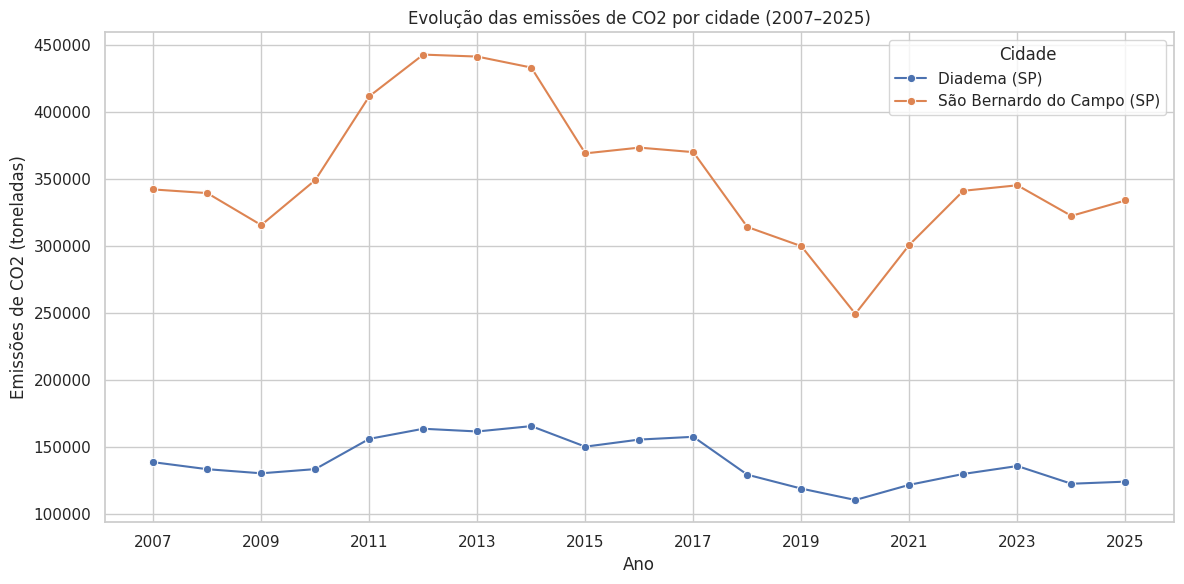

In [82]:
# Gráfico 1 - Evolução das emissões totais por cidade
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_cidade_ano,
    x='Ano',
    y='Emissao_CO2_t',
    hue='Cidade',
    marker='o'
)

plt.title('Evolução das emissões de CO2 por cidade (2007–2025)')
plt.xlabel('Ano')
plt.ylabel('Emissões de CO2 (toneladas)')
plt.xticks(range(2007, 2026, 2))
plt.legend(title='Cidade')
plt.tight_layout()
plt.show()


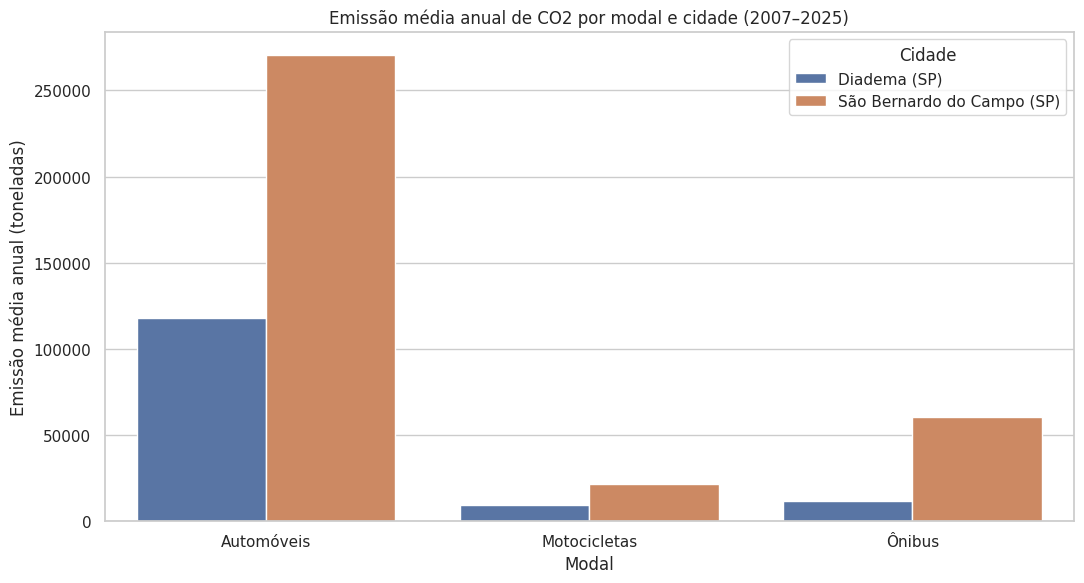

In [83]:
# Gráfico 2 - Comparação das emissões médias por modal

plt.figure(figsize=(11, 6))

sns.barplot(
    data=estatisticas_modal,
    x='Detalhamento',
    y='Media',
    hue='Cidade'
)

plt.title('Emissão média anual de CO2 por modal e cidade (2007–2025)')
plt.xlabel('Modal')
plt.ylabel('Emissão média anual (toneladas)')
plt.legend(title='Cidade')
plt.tight_layout()
plt.show()


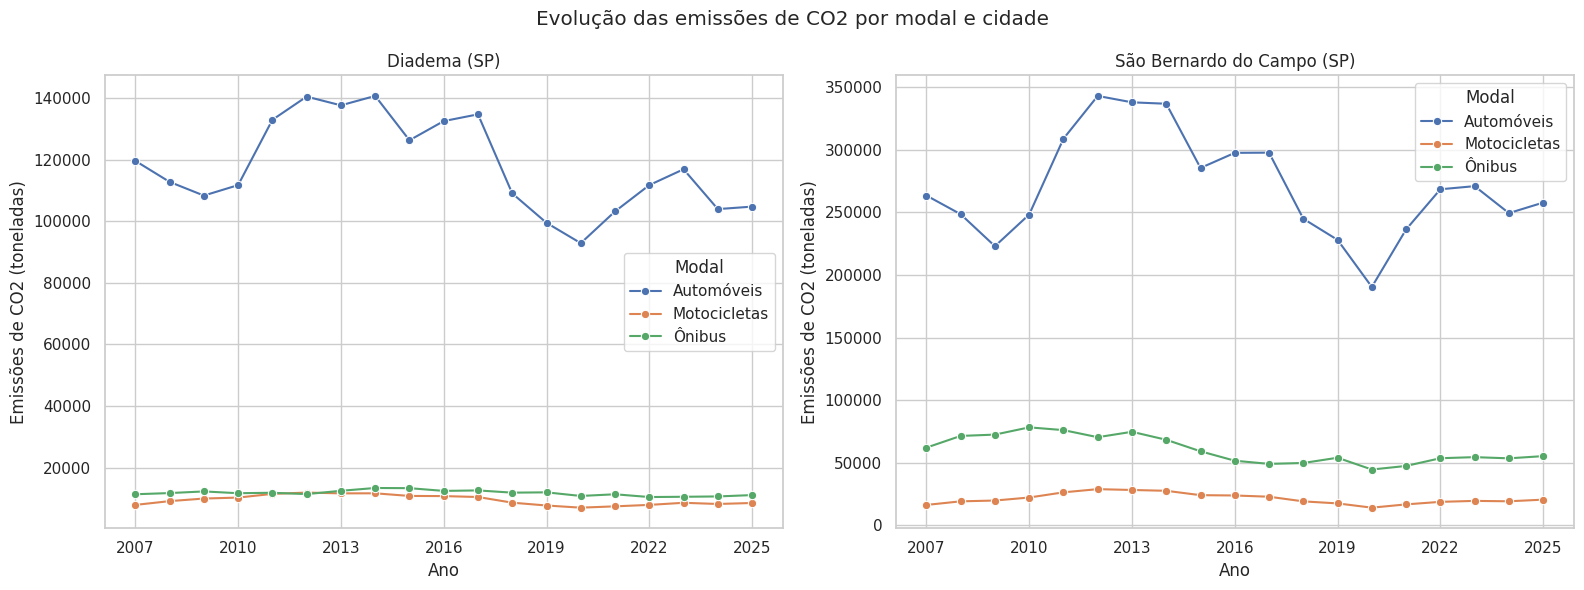

In [84]:
# Gráfico 3 - Evolução anual por modal e cidade


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

cidades = df_agregado['Cidade'].unique()

for ax, cidade in zip(axes, cidades):
    dados = df_agregado[df_agregado['Cidade'] == cidade]

    sns.lineplot(
        data=dados,
        x='Ano',
        y='Emissao_CO2_t',
        hue='Detalhamento',
        marker='o',
        ax=ax
    )

    ax.set_title(cidade)
    ax.set_xlabel('Ano')
    ax.set_ylabel('Emissões de CO2 (toneladas)')
    ax.set_xticks(range(2007, 2026, 3))

    ax.legend(title='Modal')

plt.suptitle('Evolução das emissões de CO2 por modal e cidade')
plt.tight_layout()
plt.show()


## 4.4 Regressão Linear

In [40]:
# Regressão Linear por cidade
from scipy.stats import linregress

resultados_regressao = []

for cidade in df_cidade_ano['Cidade'].unique():

    dados = df_cidade_ano[
        df_cidade_ano['Cidade'] == cidade
    ].sort_values('Ano')

    resultado = linregress(
        dados['Ano'],
        dados['Emissao_CO2_t']
    )

    resultados_regressao.append({
        'Cidade': cidade,
        'Inclinação_t_ano': resultado.slope,
        'Intercepto': resultado.intercept,
        'Correlacao_r': resultado.rvalue,
        'R2': resultado.rvalue ** 2,
        'Valor_p': resultado.pvalue
    })

tabela_regressao = pd.DataFrame(resultados_regressao)

display(tabela_regressao.round(4))


,Cidade,Inclinação_t_ano,Intercepto,Correlacao_r,R2,Valor_p
0,Diadema (SP),"-1,364.0489","2,888,890.4205",-0.4527,0.2050,0.0516
1,São Bernardo do Campo (SP),"-3,574.1223","7,557,640.5355",-0.3911,0.1530,0.0977


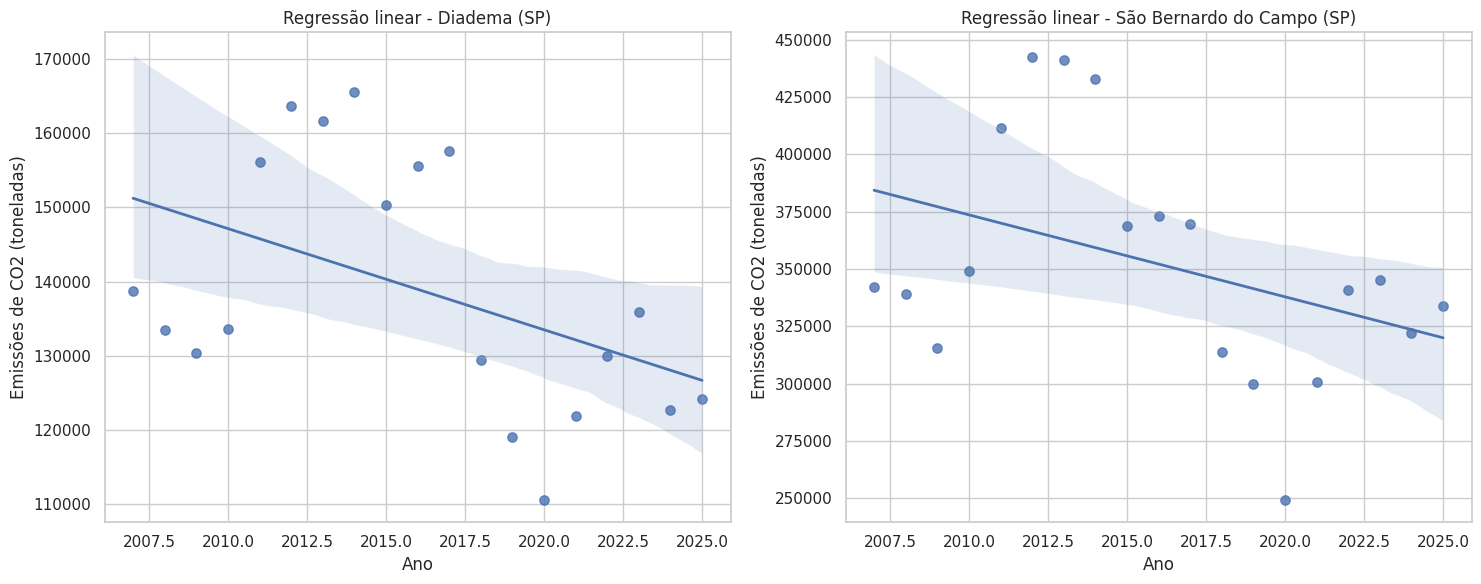

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cidades = df_cidade_ano['Cidade'].unique()

for ax, cidade in zip(axes, cidades):

    dados = df_cidade_ano[
        df_cidade_ano['Cidade'] == cidade
    ].sort_values('Ano')

    sns.regplot(
        data=dados,
        x='Ano',
        y='Emissao_CO2_t',
        ci=95,
        ax=ax,
        scatter_kws={'s': 45},
        line_kws={'linewidth': 2}
    )

    ax.set_title(f'Regressão linear - {cidade}')
    ax.set_xlabel('Ano')
    ax.set_ylabel('Emissões de CO2 (toneladas)')

plt.tight_layout()
plt.show()


# Parte II - Base de dados IBGE (dados populacionais)


# 1. EXTRAÇÃO (Extract)
Coleta de dados brutos, arquivo CSV

## Preparação do ambiente

In [42]:
# Instalando biblioteca para ler r
!pip -q install pyreadr

In [43]:
# Importando biblioteca r
import pyreadr

# Ler os dados
dados = pyreadr.read_r("/content/ibge_pop.rds")
populacao = dados[None]

# 2. TRANSFORMAÇÃO (Transform)

Nesta etapa, aplicamos as regras de negócio, limpamos e padronizamos os dados:
- Tratamento de dados duplicados, zerados e nulos;
- Padronização de formatos;
- Criação de novos campos.

In [44]:
# Filtrar o município pelo período

codigos = [3513801, 3548708]

populacao["code_muni"] = populacao["code_muni"].astype(int)
populacao["year"] = populacao["year"].astype(int)

populacao = populacao[
    (populacao["code_muni"].isin(codigos)) &
    (populacao["year"].between(2007, 2025))
].copy()

In [45]:
# Identificar os municipios
nomes = {
    3513801: "Diadema (SP)",
    3548708: "São Bernardo do Campo (SP)"
}

populacao["Cidade"] = populacao["code_muni"].map(nomes)

populacao = populacao.rename(columns={
    "year": "Ano",
    "pop": "Populacao"
})

In [46]:
# Organizar a tabela
tabela_populacao = populacao[
    ["Ano", "code_muni", "Cidade", "Populacao"]
].rename(columns={"code_muni": "IBGE"})

tabela_populacao = tabela_populacao.sort_values(
    ["Cidade", "Ano"]
).reset_index(drop=True)

In [47]:
# Conferir os dados ausentes
print("Quantidade de registros:", len(tabela_populacao))
print("\nRegistros por cidade:")
print(tabela_populacao.groupby("Cidade")["Ano"].count())

anos_esperados = set(range(2007, 2026))

for cidade in nomes.values():
    anos_encontrados = set(
        tabela_populacao.loc[
            tabela_populacao["Cidade"] == cidade, "Ano"
        ]
    )
    faltantes = sorted(anos_esperados - anos_encontrados)
    print(cidade, "- anos ausentes:", faltantes)


Quantidade de registros: 38

Registros por cidade:
Cidade
Diadema (SP)                  19
São Bernardo do Campo (SP)    19
Name: Ano, dtype: int64
Diadema (SP) - anos ausentes: []
São Bernardo do Campo (SP) - anos ausentes: []


In [48]:
# Visualizar a tabela
display(tabela_populacao)

,Ano,IBGE,Cidade,Populacao
0,2007,3513801,Diadema (SP),"386,779.0000"
1,2008,3513801,Diadema (SP),"394,266.0000"
2,2009,3513801,Diadema (SP),"397,738.0000"
3,2010,3513801,Diadema (SP),"386,089.0000"
4,2011,3513801,Diadema (SP),"388,576.0000"
...,...,...,...,...
33,2021,3548708,São Bernardo do Campo (SP),"849,874.0000"
34,2022,3548708,São Bernardo do Campo (SP),"810,729.0000"
35,2023,3548708,São Bernardo do Campo (SP),"810,729.0000"
36,2024,3548708,São Bernardo do Campo (SP),"840,499.0000"


# 3. CARGA (Load)

Criação da base de dados final que será utilizada na primeira análise estatística.
- df_população_municipios_2007_2025.csv

In [49]:
# Exportar CSV
tabela_populacao.to_csv(
    "/content/populacao_municipios_2007_2025.csv",
    index=False,
    encoding="utf-8-sig"
)


# Parte III - Integração das duas bases de dados

In [85]:
# Definir os anos
anos = [str(ano) for ano in range(2007, 2026)]


In [86]:
# Ler somente as colunas necessárias
colunas = [
    "Setor de emissão",
    "Categoria emissora",
    "Detalhamento",
    "Emissão/Remoção/Bunker",
    "Gás",
    "Cidade",
    "IBGE"
] + anos

dados_emissoes = pd.read_csv(
    "/content/gases_correta.csv",
    usecols=colunas,
    dtype={"IBGE": "string"},
    low_memory=False
)


In [87]:
# Aplicar os filtros
dados_filtrados = dados_emissoes[
    (dados_emissoes["Setor de emissão"] == "Energia") &
    (dados_emissoes["Categoria emissora"] == "Transportes") &
    (dados_emissoes["Gás"] == "CO2 (t)") &
    (dados_emissoes["Emissão/Remoção/Bunker"] == "Emissão") &
    (dados_emissoes["IBGE"].isin(["3513801", "3548708"])) &
    (dados_emissoes["Detalhamento"].isin([
        "Ônibus", "Automóveis", "Motocicletas"
    ]))
].copy()

In [53]:
# Garantir valores numéricos
for ano in anos:
    dados_filtrados[ano] = pd.to_numeric(
        dados_filtrados[ano], errors="coerce"
    ).fillna(0)

In [54]:
# Agrupar emissões por cidade e modal
emissoes_agrupadas = (
    dados_filtrados
    .groupby(
        ["IBGE", "Cidade", "Detalhamento"],
        as_index=False
    )[anos]
    .sum()
)

In [55]:
# Transformar formato largo em formato longo
emissoes_long = emissoes_agrupadas.melt(
    id_vars=["IBGE", "Cidade", "Detalhamento"],
    value_vars=anos,
    var_name="Ano",
    value_name="CO2_t"
)

emissoes_long = emissoes_long.rename(
    columns={"Detalhamento": "Modal"}
)

emissoes_long["Ano"] = emissoes_long["Ano"].astype(int)
emissoes_long["IBGE"] = emissoes_long["IBGE"].astype(int)

In [56]:
# Preparar população
pop = tabela_populacao.copy()

pop["IBGE"] = pop["IBGE"].astype(int)
pop["Ano"] = pop["Ano"].astype(int)

**Integração das bases de dados equivalente ao LEFT JOIN em linguagem SQL, utilizando as colunas IBGE e ANO como chaves de integração.**

In [88]:
#SELECT
#    e.*,
#    p.Populacao
#FROM emissoes_long AS e
#LEFT JOIN pop AS p
#    ON e.IBGE = p.IBGE
#    AND e.Ano = p.Ano;

In [57]:
# Integrar as bases
df_final = emissoes_long.merge(
    pop[["IBGE", "Ano", "Populacao"]],
    on=["IBGE", "Ano"],
    how="left",
    validate="many_to_one",
    indicator=True
)

In [58]:
# Verificar integração
print("Resultado da integração:")
print(df_final["_merge"].value_counts())

assert df_final["Populacao"].notna().all(), \
    "Existem registros sem população!"

Resultado da integração:
_merge
both          114
left_only       0
right_only      0
Name: count, dtype: int64


In [59]:
# Calcular CO2 por habitante
df_final["CO2_por_habitante"] = (
    df_final["CO2_t"] / df_final["Populacao"]
)

df_final = df_final.drop(columns="_merge")

In [60]:
# Visualizar resultado
df_final = df_final.sort_values(
    ["Ano", "Cidade", "Modal"]
).reset_index(drop=True)

display(df_final)

,IBGE,Cidade,Modal,Ano,CO2_t,Populacao,CO2_por_habitante
0,3513801,Diadema (SP),Automóveis,2007,"119,559.4988","386,779.0000",0.3091
1,3513801,Diadema (SP),Motocicletas,2007,"7,855.0523","386,779.0000",0.0203
2,3513801,Diadema (SP),Ônibus,2007,"11,316.2315","386,779.0000",0.0293
3,3548708,São Bernardo do Campo (SP),Automóveis,2007,"263,547.6175","781,390.0000",0.3373
4,3548708,São Bernardo do Campo (SP),Motocicletas,2007,"16,357.9820","781,390.0000",0.0209
...,...,...,...,...,...,...,...
109,3513801,Diadema (SP),Motocicletas,2025,"8,479.3752","403,579.0000",0.0210
110,3513801,Diadema (SP),Ônibus,2025,"11,045.1270","403,579.0000",0.0274
111,3548708,São Bernardo do Campo (SP),Automóveis,2025,"257,887.0786","841,154.0000",0.3066
112,3548708,São Bernardo do Campo (SP),Motocicletas,2025,"20,577.7466","841,154.0000",0.0245


In [61]:
# Exportar resultado
df_final.to_csv(
    "/content/emissoes_CO2_por_habitante.csv",
    index=False,
    encoding="utf-8-sig"
)

In [62]:
from google.colab import files

# Exporta o DataFrame para a pasta atual
df_final.to_csv('emissoes_CO2_por_habitante.csv', index=False, encoding='utf-8-sig')

# Faz o download automático do arquivo para o seu computador
files.download('emissoes_CO2_por_habitante.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
# Exportando o DataFrame df_final para um arquivo CSV usando Pandas
df_final.to_csv('meu_arquivo_exportado.csv', index=False, encoding='utf-8-sig')
print("DataFrame exportado com sucesso para 'meu_arquivo_exportado.csv'!")

DataFrame exportado com sucesso para 'meu_arquivo_exportado.csv'!


# Parte IV - Consolidação e comparação dos resultados

In [64]:
# Consolidar os três modais por cidade e ano
df_cidades = (
    df_final
    .groupby(["IBGE", "Cidade", "Ano"], as_index=False)
    .agg(
        CO2_total_t=("CO2_t", "sum"),
        Populacao=("Populacao", "first")
    )
)

In [65]:
# Calcular emissão total por habitante
df_cidades["CO2_por_habitante"] = (
    df_cidades["CO2_total_t"] / df_cidades["Populacao"]
)

In [66]:
# Conferir a estrutura
print("Quantidade de registros:", len(df_cidades))
print("Valores ausentes:")
print(df_cidades.isnull().sum())

Quantidade de registros: 38
Valores ausentes:
IBGE                 0
Cidade               0
Ano                  0
CO2_total_t          0
Populacao            0
CO2_por_habitante    0
dtype: int64


In [67]:
# Comparar os anos inicial e final
comparacao = df_cidades[
    df_cidades["Ano"].isin([2007, 2025])
].copy()

display(comparacao)


,IBGE,Cidade,Ano,CO2_total_t,Populacao,CO2_por_habitante
0,3513801,Diadema (SP),2007,"138,730.7826","386,779.0000",0.3587
18,3513801,Diadema (SP),2025,"124,226.8609","403,579.0000",0.3078
19,3548708,São Bernardo do Campo (SP),2007,"342,033.4158","781,390.0000",0.4377
37,3548708,São Bernardo do Campo (SP),2025,"333,812.0185","841,154.0000",0.3969


In [68]:
# Calcular a variação percentual de 2007 a 2025
resultados = []

for cidade, grupo in df_cidades.groupby("Cidade"):

    inicial = grupo.loc[
        grupo["Ano"] == 2007
    ].iloc[0]

    final = grupo.loc[
        grupo["Ano"] == 2025
    ].iloc[0]

    variacao_total = (
        (final["CO2_total_t"] / inicial["CO2_total_t"]) - 1
    ) * 100

    variacao_hab = (
        (final["CO2_por_habitante"] /
         inicial["CO2_por_habitante"]) - 1
    ) * 100

    resultados.append({
        "Cidade": cidade,
        "CO2_2007": inicial["CO2_total_t"],
        "CO2_2025": final["CO2_total_t"],
        "Variacao_CO2_%": variacao_total,
        "CO2_hab_2007": inicial["CO2_por_habitante"],
        "CO2_hab_2025": final["CO2_por_habitante"],
        "Variacao_CO2_hab_%": variacao_hab
    })

df_comparacao = pd.DataFrame(resultados)

display(df_comparacao.round(4))


,Cidade,CO2_2007,CO2_2025,Variacao_CO2_%,CO2_hab_2007,CO2_hab_2025,Variacao_CO2_hab_%
0,Diadema (SP),"138,730.7826","124,226.8609",-10.4547,0.3587,0.3078,-14.1823
1,São Bernardo do Campo (SP),"342,033.4158","333,812.0185",-2.4037,0.4377,0.3969,-9.3379


In [69]:
# Calcular inclinação das tendências por habitante
for cidade, grupo in df_cidades.groupby("Cidade"):

    inclinacao = np.polyfit(
        grupo["Ano"],
        grupo["CO2_por_habitante"],
        1
    )[0]

    print(
        f"{cidade}: inclinação = "
        f"{inclinacao:.6f} t CO2/hab. por ano"
    )


Diadema (SP): inclinação = -0.004329 t CO2/hab. por ano
São Bernardo do Campo (SP): inclinação = -0.006200 t CO2/hab. por ano


## Retas de tendência

In [70]:
resultados_tendencia = []

for cidade, grupo in df_cidades.groupby("Cidade"):

    grupo = grupo.sort_values("Ano")

    # Regressão das emissões totais
    coef_total = np.polyfit(
        grupo["Ano"],
        grupo["CO2_total_t"],
        1
    )

    # Regressão das emissões por habitante
    coef_hab = np.polyfit(
        grupo["Ano"],
        grupo["CO2_por_habitante"],
        1
    )

    resultados_tendencia.append({
        "Cidade": cidade,
        "Inclinacao_CO2_total": coef_total[0],
        "Inclinacao_CO2_habitante": coef_hab[0]
    })

df_tendencias = pd.DataFrame(resultados_tendencia)

display(df_tendencias.round(6))

# Verificar qual cidade emitiu mais em cada ano
comparacao_anual = df_cidades.pivot(
    index="Ano",
    columns="Cidade",
    values="CO2_total_t"
)

comparacao_anual["Cidade_maior_emissao"] = np.where(
    comparacao_anual["Diadema (SP)"] >
    comparacao_anual["São Bernardo do Campo (SP)"],
    "Diadema (SP)",
    "São Bernardo do Campo (SP)"
)

display(comparacao_anual)


,Cidade,Inclinacao_CO2_total,Inclinacao_CO2_habitante
0,Diadema (SP),"-1,364.0489",-0.0043
1,São Bernardo do Campo (SP),"-3,574.1223",-0.0062


Cidade,Diadema (SP),São Bernardo do Campo (SP),Cidade_maior_emissao
Ano,,,
2007,"138,730.7826","342,033.4158",São Bernardo do Campo (SP)
2008,"133,509.9556","339,320.6381",São Bernardo do Campo (SP)
2009,"130,439.4852","315,471.1873",São Bernardo do Campo (SP)
2010,"133,574.3147","348,993.0376",São Bernardo do Campo (SP)
2011,"156,119.8863","411,463.3313",São Bernardo do Campo (SP)
2012,"163,649.1641","442,548.5175",São Bernardo do Campo (SP)
2013,"161,626.3700","441,084.9034",São Bernardo do Campo (SP)
2014,"165,613.1090","432,898.4551",São Bernardo do Campo (SP)
2015,"150,306.7403","368,924.0921",São Bernardo do Campo (SP)


In [71]:

# Calcular R² para emissões totais e por habitante

resultados_r2 = []

variaveis = {
    "CO2_total_t": "Emissões totais",
    "CO2_por_habitante": "Emissões por habitante"
}

for cidade in cidades:

    grupo = df_cidades[
        df_cidades["Cidade"] == cidade
    ].sort_values("Ano")

    x = grupo["Ano"].values

    for coluna, descricao in variaveis.items():

        y = grupo[coluna].values

        # Regressão linear
        coef = np.polyfit(x, y, 1)
        valores_estimados = np.polyval(coef, x)

        # Coeficiente de determinação
        soma_residuos = np.sum(
            (y - valores_estimados) ** 2
        )

        soma_total = np.sum(
            (y - np.mean(y)) ** 2
        )

        r2 = 1 - (soma_residuos / soma_total)

        resultados_r2.append({
            "Cidade": cidade,
            "Indicador": descricao,
            "R2": r2
        })

df_r2 = pd.DataFrame(resultados_r2)

display(df_r2.round(4))


,Cidade,Indicador,R2
0,Diadema (SP),Emissões totais,0.2050
1,Diadema (SP),Emissões por habitante,0.2836
2,São Bernardo do Campo (SP),Emissões totais,0.1530
3,São Bernardo do Campo (SP),Emissões por habitante,0.2329


In [72]:
resultados_r2_modais = []

for cidade in cidades:
    for modal in modais:

        grupo = df_final[
            (df_final["Cidade"] == cidade) &
            (df_final["Modal"] == modal)
        ].sort_values("Ano")

        x = grupo["Ano"].values
        y = grupo["CO2_t"].values

        coef = np.polyfit(x, y, 1)
        estimados = np.polyval(coef, x)

        sse = np.sum((y - estimados) ** 2)
        sst = np.sum((y - np.mean(y)) ** 2)

        r2 = 1 - sse / sst if sst != 0 else np.nan

        resultados_r2_modais.append({
            "Cidade": cidade,
            "Modal": modal,
            "R2": r2
        })

df_r2_modais = pd.DataFrame(resultados_r2_modais)

display(df_r2_modais.round(4))


,Cidade,Modal,R2
0,Diadema (SP),Ônibus,0.2187
1,Diadema (SP),Automóveis,0.1853
2,Diadema (SP),Motocicletas,0.2604
3,São Bernardo do Campo (SP),Ônibus,0.5712
4,São Bernardo do Campo (SP),Automóveis,0.0631
5,São Bernardo do Campo (SP),Motocicletas,0.1085


In [73]:
# FUNÇÃO DE REGRESSÃO LINEAR E R²
def calcular_tendencia(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Remover valores ausentes
    validos = np.isfinite(x) & np.isfinite(y)
    x = x[validos]
    y = y[validos]

    if len(x) < 2 or len(np.unique(x)) < 2:
        raise ValueError("Dados insuficientes para regressão.")

    # Centralizar os anos
    x_centro = x - x.mean()

    coef = np.polyfit(x_centro, y, 1)
    tendencia = np.polyval(coef, x_centro)

    # Calcular R²
    ss_res = np.sum((y - tendencia) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)

    r2 = 1 - (ss_res / ss_tot) if ss_tot > 0 else np.nan

    return tendencia, r2

In [74]:
# FUNÇÃO PARA VALIDAR AS SÉRIES

def validar_serie(grupo, coluna):

    grupo = grupo.sort_values("Ano").copy()

    if grupo["Ano"].duplicated().any():
        raise ValueError("Existem anos duplicados na série.")

    anos_encontrados = set(grupo["Ano"].astype(int))

    if anos_encontrados != anos_esperados:
        print("ATENÇÃO: série incompleta.")
        print("Anos ausentes:", sorted(
            anos_esperados - anos_encontrados
        ))

    grupo[coluna] = pd.to_numeric(
        grupo[coluna], errors="coerce"
    )

    if grupo[coluna].isna().any():
        raise ValueError("Existem valores ausentes na série.")

    return grupo

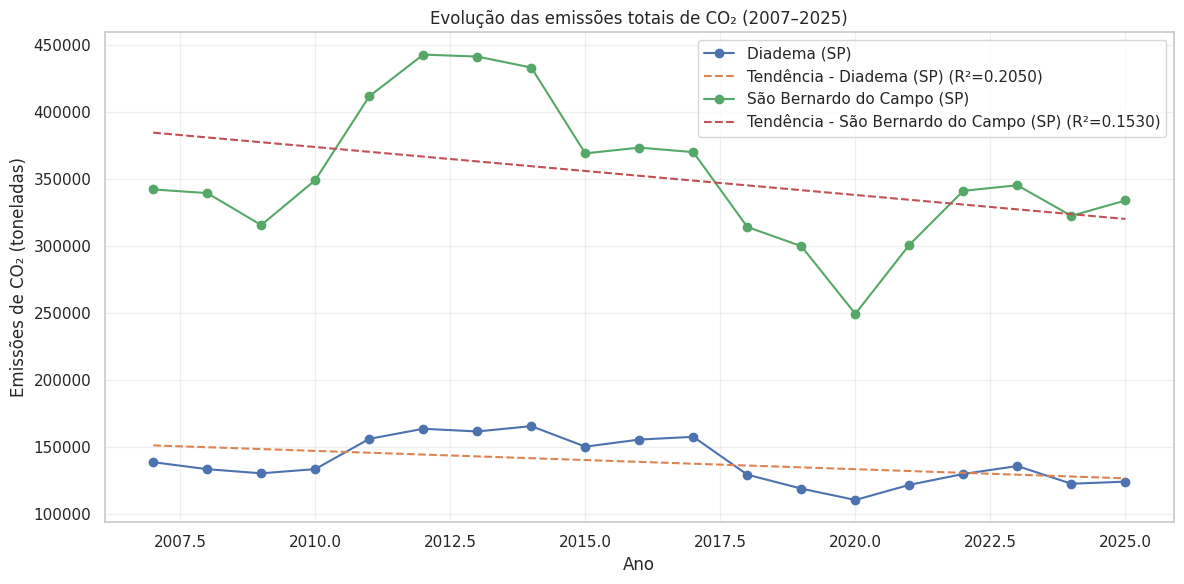

In [75]:
# GRÁFICO 1 - EMISSÕES TOTAIS

plt.figure(figsize=(12, 6))

for cidade in cidades:

    grupo = df_cidades[
        df_cidades["Cidade"] == cidade
    ]

    grupo = validar_serie(grupo, "CO2_total_t")

    x = grupo["Ano"].values
    y = grupo["CO2_total_t"].values

    tendencia, r2 = calcular_tendencia(x, y)

    plt.plot(
        x, y,
        marker="o",
        label=cidade
    )

    plt.plot(
        x, tendencia,
        linestyle="--",
        label=f"Tendência - {cidade} (R²={r2:.4f})"
    )

plt.title("Evolução das emissões totais de CO₂ (2007–2025)")
plt.xlabel("Ano")
plt.ylabel("Emissões de CO₂ (toneladas)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

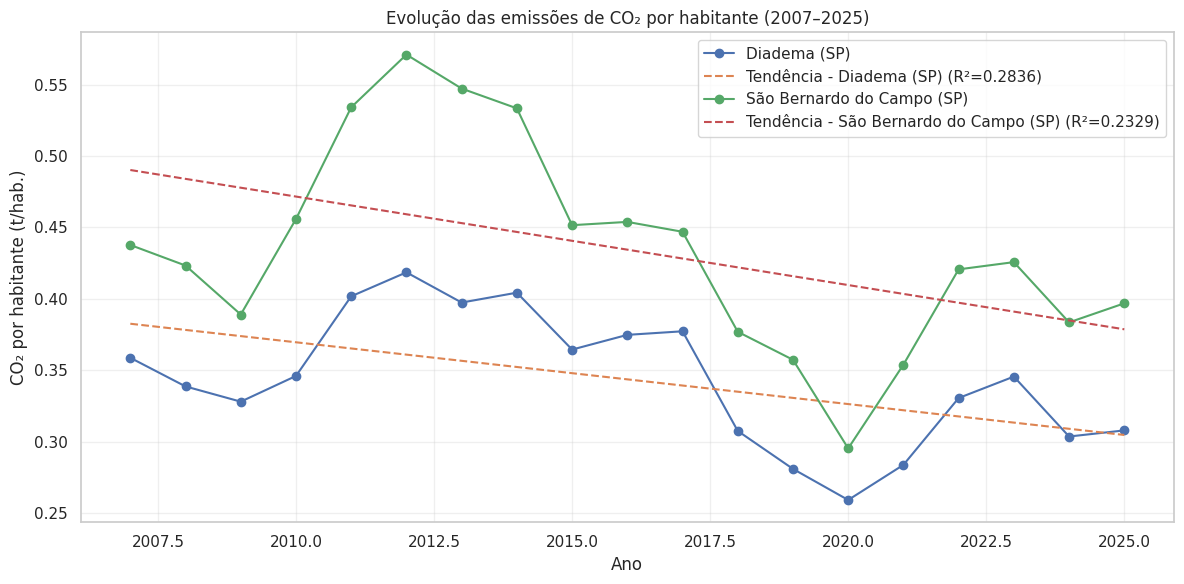

In [76]:
# GRÁFICO 2 - EMISSÕES POR HABITANTE

plt.figure(figsize=(12, 6))

for cidade in cidades:

    grupo = df_cidades[
        df_cidades["Cidade"] == cidade
    ]

    grupo = validar_serie(
        grupo, "CO2_por_habitante"
    )

    x = grupo["Ano"].values
    y = grupo["CO2_por_habitante"].values

    tendencia, r2 = calcular_tendencia(x, y)

    plt.plot(
        x, y,
        marker="o",
        label=cidade
    )

    plt.plot(
        x, tendencia,
        linestyle="--",
        label=f"Tendência - {cidade} (R²={r2:.4f})"
    )

plt.title("Evolução das emissões de CO₂ por habitante (2007–2025)")
plt.xlabel("Ano")
plt.ylabel("CO₂ por habitante (t/hab.)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

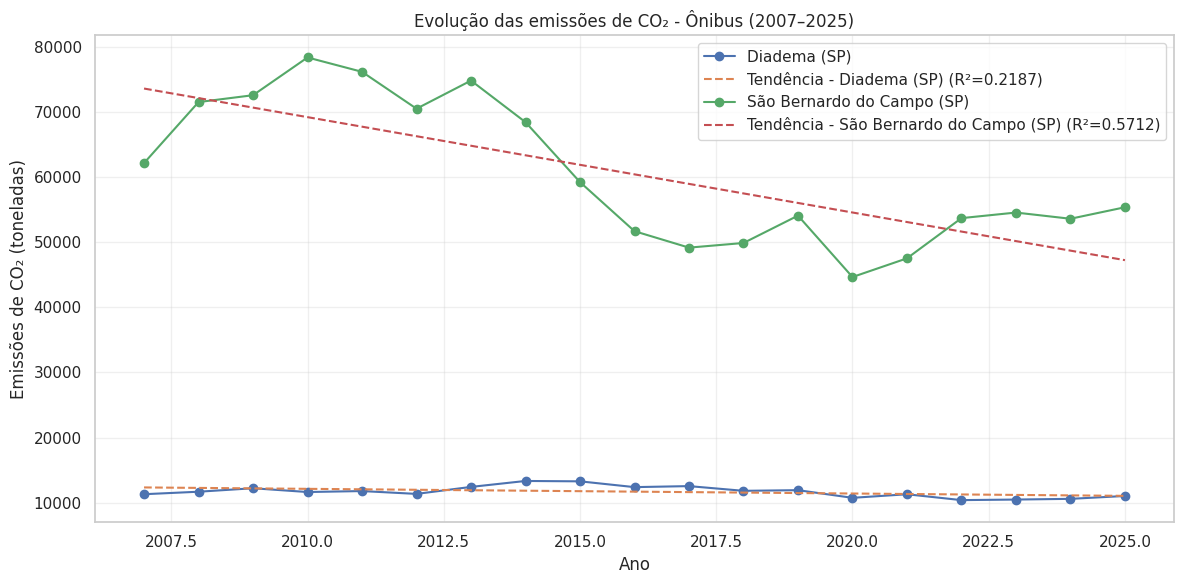

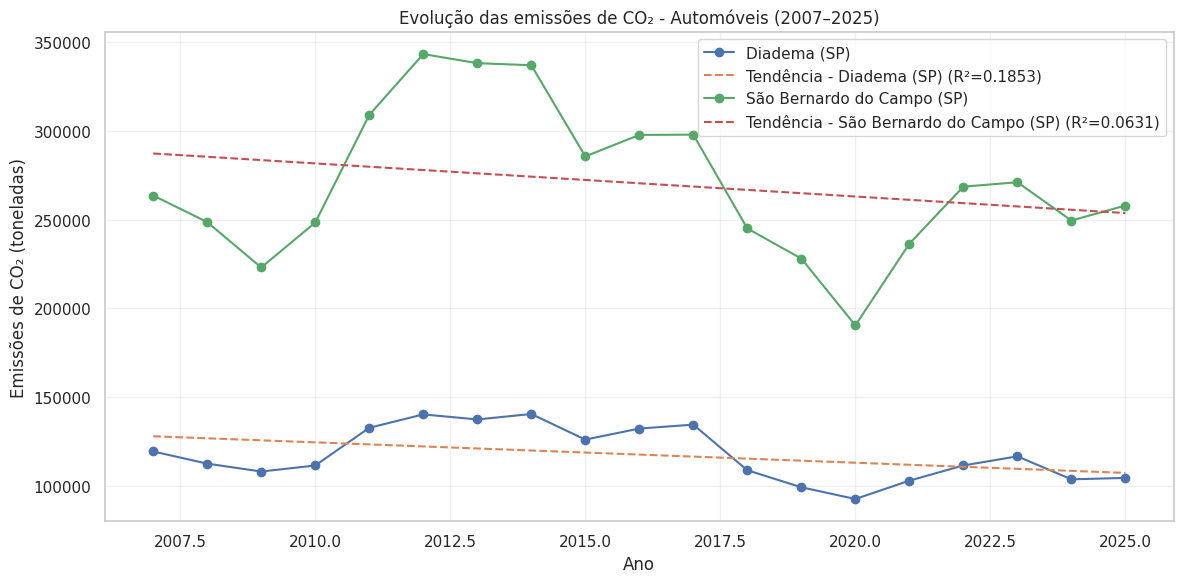

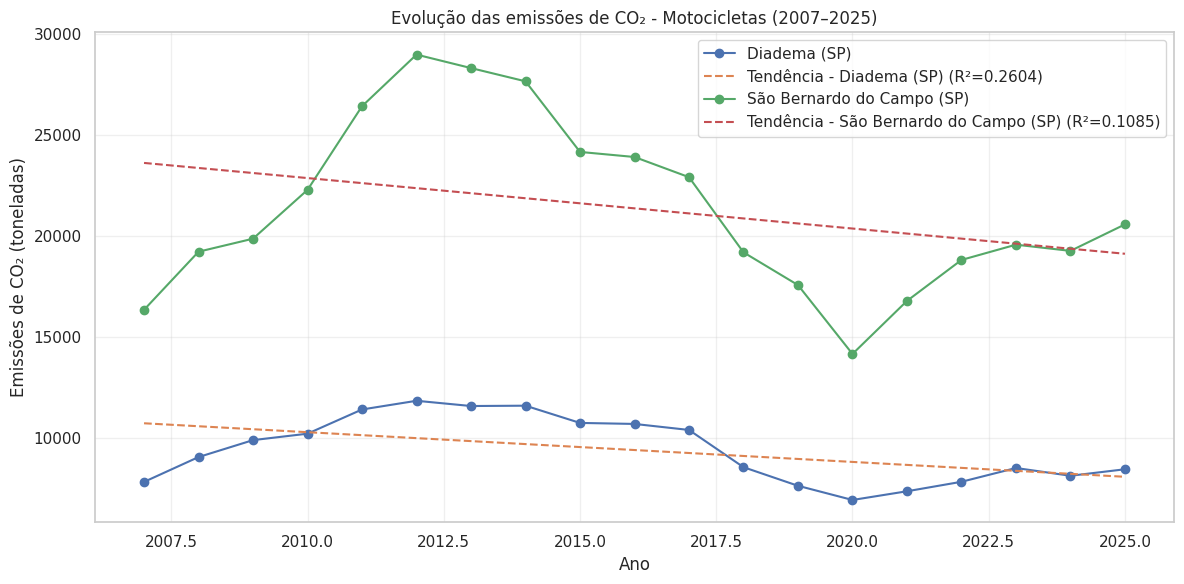

In [77]:
# GRÁFICO 3 - COMPARAÇÃO DOS MODAIS

for modal in modais:

    plt.figure(figsize=(12, 6))

    for cidade in cidades:

        grupo = df_final[
            (df_final["Cidade"] == cidade) &
            (df_final["Modal"] == modal)
        ]

        grupo = validar_serie(grupo, "CO2_t")

        x = grupo["Ano"].values
        y = grupo["CO2_t"].values

        tendencia, r2 = calcular_tendencia(x, y)

        plt.plot(
            x, y,
            marker="o",
            label=cidade
        )

        plt.plot(
            x, tendencia,
            linestyle="--",
            label=f"Tendência - {cidade} (R²={r2:.4f})"
        )

    plt.title(
        f"Evolução das emissões de CO₂ - {modal} (2007–2025)"
    )

    plt.xlabel("Ano")
    plt.ylabel("Emissões de CO₂ (toneladas)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [78]:
df_final.to_csv('df_final.csv', index=False, encoding='utf-8-sig')